# PhishGuard: LightGBM (Branch A)


## 1. Load data and split

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

DARK, LIGHT = "#08306b", "#6baed6"

train = pd.read_csv(r"D:\Python\gproject\project\preprocessed_train_pca.csv")
test  = pd.read_csv(r"D:\Python\gproject\project\preprocessed_test_pca.csv")

X, y = train.drop(columns=["target"]), train["target"]
X_test, y_test = test.drop(columns=["target"]), test["target"]

# 20% of train is held out for early stopping / tuning
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_tr.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print("Train class share:\n", y.value_counts(normalize=True).round(3))

Train: (38300, 25) | Val: (9575, 25) | Test: (11970, 25)
Train class share:
 target
1    0.526
0    0.474
Name: proportion, dtype: float64


## 2. Baseline model

In [15]:
baseline = lgb.LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1,
)

baseline.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(50, verbose=False)],
)

baseline_auc = roc_auc_score(y_val, baseline.predict_proba(X_val)[:, 1])
print("Baseline val AUC:", round(baseline_auc, 5))

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

Baseline val AUC: 0.99969


## 3. Hyperparameter tuning (Optuna)
Uses only the validation split, never the test file.

In [17]:
%pip install optuna
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        "n_estimators": 2000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 100),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "random_state": 42,
        "verbose": -1,
    }
    m = lgb.LGBMClassifier(**params)
    m.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        eval_metric="auc",
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    return roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50, show_progress_bar=True)

print("Best val AUC:", round(study.best_value, 5))
print(study.best_params)

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/442.4 kB ? eta -:--:--
   -- ------------------------------------- 30.7/442.4 kB ? eta -:--:--
   ----- --------------------------------- 61.4/442.4 kB 656.4 kB/s eta 0:00:01
   --------- ---------------------------- 112.6/442.4 kB 819.2 kB/s eta 0:00:01
   ----------------- ---------------------- 194.6/442.4 kB 1.2 MB/s eta 0:00:01
   ------------------------- -------------- 276.5/442.4 kB 1.4 MB/s eta 0:00:01
   ------------------------------------- -- 419.8/442.4 kB 1.6 MB/s eta 0:00:01
   ---------------------------------------- 442.4/442.4 kB 1.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/268.7 kB ? eta -:--:--
   --------------------- ------------------ 143.4/268.7 kB 4.2 MB/s eta 0:00:01
   ---------------------------------------- 268.7/268.7 kB 3.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/80.2 kB ? eta -:--:-

DEPRECATION: Loading egg at c:\programdata\anaconda3\lib\site-packages\vboxapi-1.0-py3.12.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation.. Discussion can be found at https://github.com/pypa/pip/issues/12330


  0%|          | 0/50 [00:00<?, ?it/s]

Best val AUC: 0.99979
{'learning_rate': 0.012510189048636062, 'num_leaves': 69, 'min_child_samples': 65, 'subsample': 0.6174569552786782, 'colsample_bytree': 0.6800915286727722, 'reg_alpha': 0.02059409557016706, 'reg_lambda': 0.001241485979896052}


## 4. Train the tuned model and compare with baseline

In [18]:
tuned = lgb.LGBMClassifier(
    n_estimators=2000,
    subsample_freq=1,
    random_state=42,
    verbose=-1,
    **study.best_params,
)

tuned.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(50, verbose=False)],
)

tuned_auc = roc_auc_score(y_val, tuned.predict_proba(X_val)[:, 1])
print(f"Baseline val AUC: {baseline_auc:.5f}")
print(f"Tuned    val AUC: {tuned_auc:.5f}")

# Keep whichever is better
model = tuned if tuned_auc >= baseline_auc else baseline
print("Using:", "tuned" if model is tuned else "baseline")

Baseline val AUC: 0.99969
Tuned    val AUC: 0.99979
Using: tuned


## 5. Evaluate on the test file

              precision    recall  f1-score   support

           0     0.9942    0.9988    0.9965      5672
           1     0.9989    0.9948    0.9968      6298

    accuracy                         0.9967     11970
   macro avg     0.9965    0.9968    0.9966     11970
weighted avg     0.9967    0.9967    0.9967     11970

Test ROC AUC: 0.99973


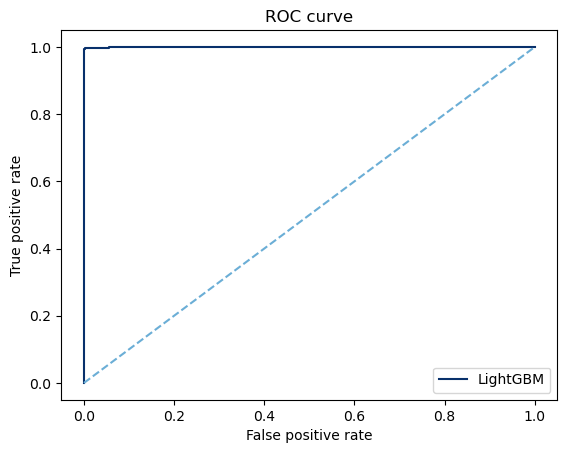

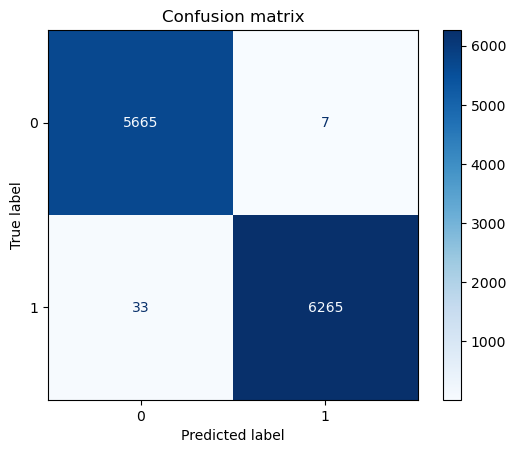

In [19]:
from sklearn.metrics import (classification_report, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

pred  = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred, digits=4))
print("Test ROC AUC:", round(roc_auc_score(y_test, proba), 5))

# ROC curve
fpr, tpr, _ = roc_curve(y_test, proba)
plt.plot(fpr, tpr, color=DARK, label="LightGBM")
plt.plot([0, 1], [0, 1], color=LIGHT, linestyle="--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend()
plt.show()

# Confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(cmap="Blues")
plt.title("Confusion matrix")
plt.show()

## Conclusion: Confusion Matrix

- **Correct predictions:** 5,665 legit and 6,265 phishing URLs (11,930 of 11,970, accuracy 99.67%).
- **False positives:** 7 legit URLs flagged as phishing (0.12% of legit URLs).
- **False negatives:** 33 phishing URLs missed (0.52% of phishing URLs, recall 0.9948).
- **Main weakness:** missed phishing (33) is about 5 times more common than false alarms (7). Lowering the threshold below 0.5 could trade a few extra false alarms for fewer misses.

## 6. Threshold check (recall matters most for phishing)

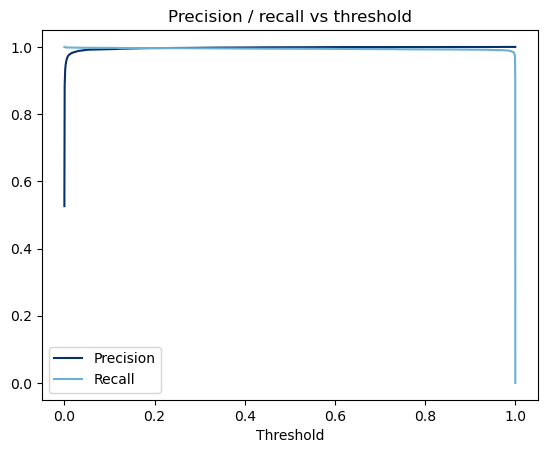

In [20]:
from sklearn.metrics import precision_recall_curve

prec, rec, thr = precision_recall_curve(y_test, proba)
plt.plot(thr, prec[:-1], color=DARK, label="Precision")
plt.plot(thr, rec[:-1], color=LIGHT, label="Recall")
plt.xlabel("Threshold")
plt.title("Precision / recall vs threshold")
plt.legend()
plt.show()

## Conclusion: Precision / Recall vs Threshold

- **Default threshold (0.5):** phishing precision = 0.9989, recall = 0.9948 (test set).
- **Stable range:** from about 0.05 to 0.95, both precision and recall stay at roughly 0.99 or higher, so the model is not sensitive to the threshold.
- **Low thresholds (below about 0.05):** almost every URL is flagged, so recall is about 1.0 and precision drops to about 0.53 (the share of phishing URLs in the test set).
- **High thresholds (above about 0.95):** almost nothing is flagged, so recall drops to 0.
- **Why the curves are flat:** the model gives most URLs a probability close to 0 or 1, so moving the threshold changes few predictions.
- **Decision:** keep the threshold at 0.5. Lower it only if missing phishing URLs costs more than false alarms.
- **Limitation:** the data comes from two sources (PhishTank and Tranco), so performance on real-world URLs may be lower.

## 7. Save the model for Branch A


In [21]:
import joblib
joblib.dump(model, "phishguard_lgbm.pkl")
print("Saved phishguard_lgbm.pkl")

Saved phishguard_lgbm.pkl
